# SHIELD — Vision-Based Driver Drowsiness Detection (v2)

**Feature enhancements in v2** (Sections 10–17, after the original Sections 1–9):
1. **Face & eye region extraction** — the face is detected and cropped, and the eye region is extracted from it, so the model focuses on the most important drowsiness cues.
2. **Illumination normalization (CLAHE)** — contrast-limited adaptive histogram equalization makes dark or unevenly lit cabin images clearer.
3. **Two-stream Face + Eye network (proposed SHIELD model)** — two lightweight MobileNetV3-Small branches, one for the whole face and one for the eye region, whose features are fused for the final decision.
4. **Low-light robustness test** — models are evaluated on artificially darkened test images to measure the benefit of CLAHE.
5. **Explainability** — Grad-CAM heatmaps for both the face and eye streams.
6. **Real-time demo** — the trained model is exported and used by `demo.py` for live webcam monitoring.

> Run on Google Colab with a GPU runtime (Runtime → Change runtime type → GPU).

## Section 1 — Problem Identification

### Problem
Driver drowsiness can reduce attention and increase the risk of road accidents. The project aims to build an image-classification system that distinguishes between **alert** and **drowsy** driver states.

### Machine Learning Task
This is a **binary image classification** problem:
- **Class 0:** Alert
- **Class 1:** Drowsy

### Why Deep Learning?
Driver facial/eye-related visual patterns can be learned directly from images using a CNN-based model. We use **MobileNetV3-Small** with transfer learning because it is relatively lightweight and suitable for image classification.


## Section 2 — Environment & Libraries
**Purpose:** Import the libraries required for dataset handling, image processing, numerical operations, visualization, and deep learning.


In [1]:
# Import the libraries used throughout the notebook.
# torch: deep learning framework
# cv2: OpenCV (not required by the current pipeline, but kept if later image processing is added)
# numpy/pandas: numerical and tabular operations
# matplotlib: visualization
import torch
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu130
CUDA available: True


## Section 3 — Dataset Loading
**Purpose:** Install and load the Hugging Face dataset used for the project.

**Dataset:** `chbh7051/UTA-RLDD_images`

The notebook output shows:
- Train: **5539** images
- Validation: **692** images
- Test: **693** images

The dataset contains `image_file_path`, `image`, and `labels` fields.


In [2]:
# Install the Hugging Face Datasets library.
# PyDrive2 is not needed for this notebook, so the previous uninstall cell was removed.
!pip install -q datasets


In [3]:
# Load the UTA-RLDD image dataset from Hugging Face.
from datasets import load_dataset

dataset = load_dataset(
    "chbh7051/UTA-RLDD_images",
    revision="refs/convert/parquet"
)

# Display the structure and number of examples in each split.
print(dataset)


default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  502MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/train/0001.parquet: reconstructing file:   0%|          |  0.00B /  512MB            

default/train/0001.parquet: downloading bytes:           |  0.00B            

default/train/0002.parquet: reconstructing file:   0%|          |  0.00B /  509MB            

...

default/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 5539
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 692
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 693
    })
})


Label: 0
Path: /storage/hf-datasets-cache/all/datasets/62255628904278-config-parquet-and-info-chbh7051-UTA-RLDD_images-24e51306/downloads/extracted/0496cc173bed6453f0c88aadd01848d98c37ed5a8b5c36b6b268aa4580172c65/train/alert/01_0.jpg


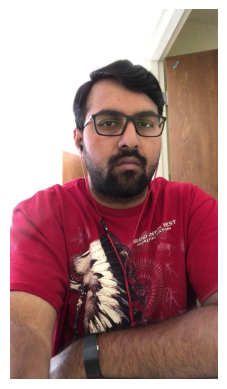

In [4]:
# Display one sample image to verify that the dataset was loaded correctly.
sample = dataset["train"][0]

print("Label:", sample["labels"])
print("Path:", sample["image_file_path"])

plt.imshow(sample["image"])
plt.axis("off")
plt.show()


## Section 4 — Dataset & Label Analysis
**Purpose:** Understand the original label encoding and class distribution before preprocessing.

The dataset's `ClassLabel` contains three names: `alert`, `low_vigilant`, and `drowsy`. In the loaded train/validation/test splits, the observed labels are **0 (alert)** and **2 (drowsy)**. The notebook therefore uses these two observed classes for binary classification.


In [5]:
# Show the original label definition provided by the dataset.
print(dataset["train"].features["labels"])


ClassLabel(names=['alert', 'low_vigilant', 'drowsy'])


In [6]:
# Count the original labels in every dataset split.
# int2str converts the numeric label ID into its human-readable class name.
from collections import Counter

for split in ["train", "validation", "test"]:
    counts = Counter(dataset[split]["labels"])

    print(f"\n{split}:")
    for label_id, count in sorted(counts.items()):
        label_name = dataset[split].features["labels"].int2str(label_id)
        print(f"{label_id} -> {label_name}: {count}")



train:
0 -> alert: 2700
2 -> drowsy: 2839

validation:
0 -> alert: 337
2 -> drowsy: 355

test:
0 -> alert: 338
2 -> drowsy: 355


In [7]:
# Convert the two observed original classes into binary labels.
# Original 0 (alert)  -> new 0 (Alert)
# Original 2 (drowsy) -> new 1 (Drowsy)
#
# Using an explicit mapping is safer than "else 1", because the dataset
# definition also contains label ID 1 (low_vigilant).
LABEL_MAP = {0: 0, 2: 1}

def convert_label(label):
    if label not in LABEL_MAP:
        raise ValueError(f"Unexpected label {label}. Expected one of {list(LABEL_MAP)}.")
    return LABEL_MAP[label]

print("alert:", convert_label(0))
print("drowsy:", convert_label(2))


alert: 0
drowsy: 1


## Section 5 — Data Preprocessing
**Purpose:** Convert raw images into a format suitable for MobileNetV3.

### Preprocessing steps
1. Resize every image to **224 × 224**.
2. Convert the image to a PyTorch tensor.
3. Normalize RGB channels using ImageNet mean/std because the pretrained MobileNetV3 weights were trained with ImageNet-style normalization.

For training, augmentation is added later:
- Random horizontal flip
- Random rotation
- Color jitter

Validation/test data do **not** use random augmentation so evaluation remains consistent.


In [8]:
# Basic preprocessing used for validation/test data.
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print(transform)


Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [10]:
# Create a PyTorch Dataset wrapper around the Hugging Face dataset.
# It converts images to RGB, maps labels to binary classes, and applies transforms.
import torch
from torch.utils.data import Dataset

class DrowsinessDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        # Ensure every image has 3 RGB channels for MobileNetV3.
        image = item["image"].convert("RGB")

        # Use the explicit binary mapping defined above.
        label = convert_label(item["labels"])

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# Create datasets using the initial deterministic transform.
train_dataset = DrowsinessDataset(dataset["train"], transform)
val_dataset = DrowsinessDataset(dataset["validation"], transform)
test_dataset = DrowsinessDataset(dataset["test"], transform)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 5539
Validation: 692
Test: 693


## Section 6 — Exploratory Data Analysis (EDA)
**Purpose:** Understand class balance, image dimensions, missing/corrupt images, and brightness characteristics before model training.


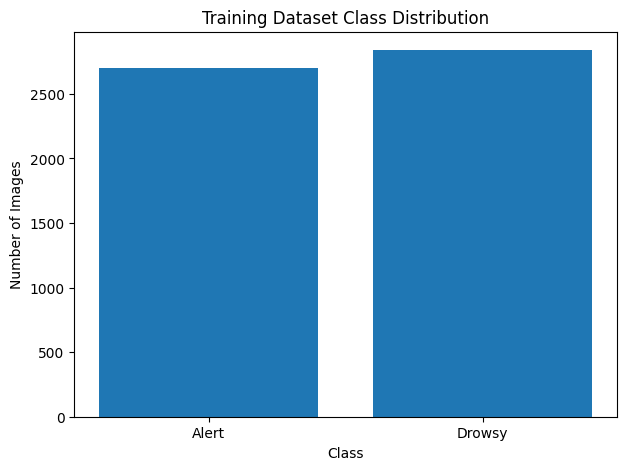

Alert: 2700
Drowsy: 2839


In [11]:
# Check the number of samples in each binary class in the training set.
from collections import Counter

counts = Counter(dataset["train"]["labels"])

labels = ["Alert", "Drowsy"]
values = [
    counts.get(0, 0),
    counts.get(2, 0)
]

plt.figure(figsize=(7, 5))
plt.bar(labels, values)
plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

print(f"Alert: {values[0]}")
print(f"Drowsy: {values[1]}")


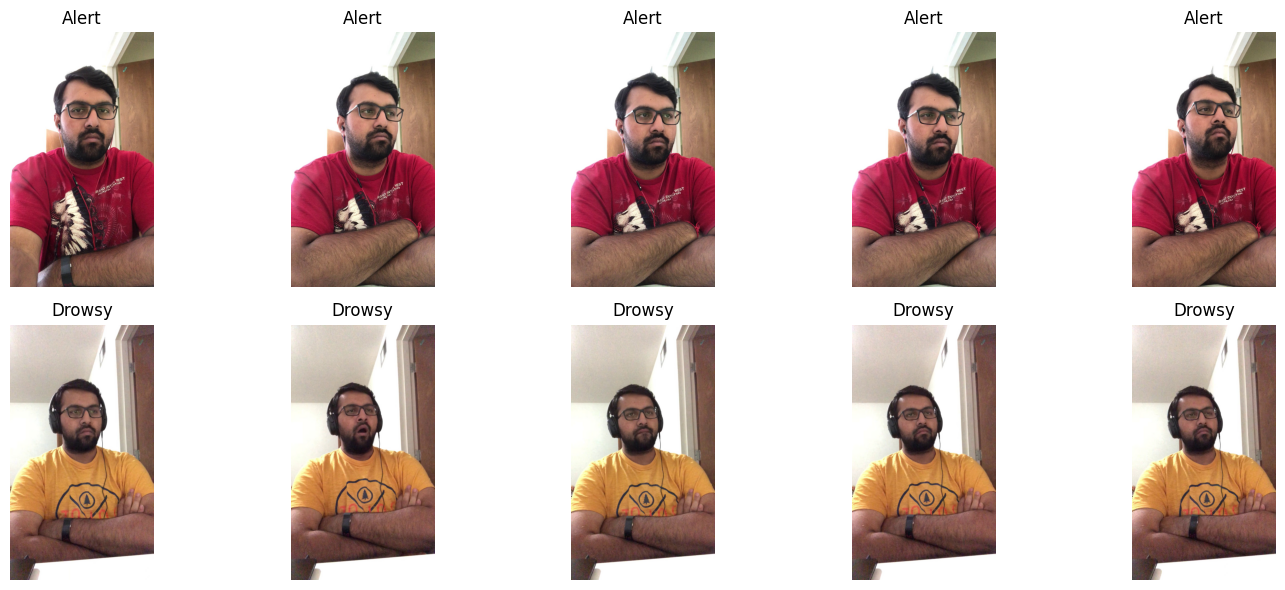

In [12]:
# Display example images from both classes.
# This is a qualitative EDA step to visually inspect the data.
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

alert_indices = [
    i for i in range(len(dataset["train"]))
    if dataset["train"][i]["labels"] == 0
][:5]

drowsy_indices = [
    i for i in range(len(dataset["train"]))
    if dataset["train"][i]["labels"] == 2
][:5]

for ax, idx in zip(axes[0], alert_indices):
    ax.imshow(dataset["train"][idx]["image"])
    ax.set_title("Alert")
    ax.axis("off")

for ax, idx in zip(axes[1], drowsy_indices):
    ax.imshow(dataset["train"][idx]["image"])
    ax.set_title("Drowsy")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [13]:
# Inspect image dimensions on a sample of up to 500 training images.
# This helps identify whether the raw dataset contains multiple resolutions.
sizes = Counter()

for i in range(min(500, len(dataset["train"]))):
    image = dataset["train"][i]["image"]
    sizes[image.size] += 1

print("Most common image sizes:")
for size, count in sizes.most_common(10):
    print(size, "->", count)


Most common image sizes:
(1080, 1920) -> 199
(480, 720) -> 52
(1440, 2560) -> 52
(1920, 1080) -> 50
(720, 1280) -> 49
(848, 480) -> 47
(320, 568) -> 43
(1280, 720) -> 8


In [14]:
# Check whether any training examples contain missing/unreadable images.
bad_images = 0

for i in range(len(dataset["train"])):
    try:
        image = dataset["train"][i]["image"]
        if image is None:
            bad_images += 1
    except Exception:
        bad_images += 1

print("Bad/missing images:", bad_images)
print("Total training images:", len(dataset["train"]))


Bad/missing images: 0
Total training images: 5539


Average brightness: 129.2982296879659
Minimum brightness: 95.8444115306713
Maximum brightness: 158.3326356738683


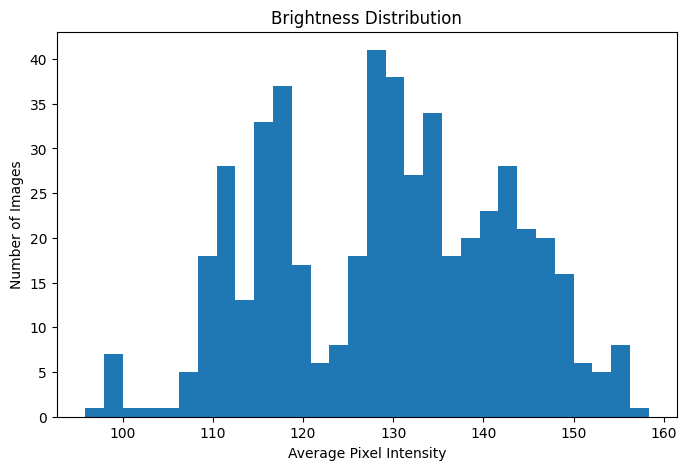

In [15]:
# Estimate average image brightness on up to 500 training images.
# Mean pixel intensity gives a simple measure of how bright/dark an image is.
brightness = []

for i in range(min(500, len(dataset["train"]))):
    image = np.array(dataset["train"][i]["image"].convert("RGB"))
    brightness.append(image.mean())

print("Average brightness:", np.mean(brightness))
print("Minimum brightness:", np.min(brightness))
print("Maximum brightness:", np.max(brightness))

plt.figure(figsize=(8, 5))
plt.hist(brightness, bins=30)
plt.title("Brightness Distribution")
plt.xlabel("Average Pixel Intensity")
plt.ylabel("Number of Images")
plt.show()


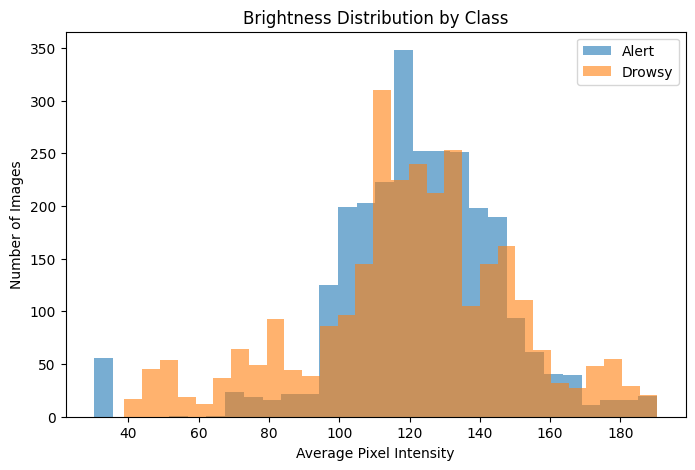

Alert mean brightness: 122.86404955250086
Drowsy mean brightness: 120.1019099735173


In [16]:
# Compare brightness distributions between Alert and Drowsy classes.
alert_brightness = []
drowsy_brightness = []

for i in range(len(dataset["train"])):
    image = np.array(dataset["train"][i]["image"].convert("RGB"))
    mean_brightness = image.mean()

    original_label = dataset["train"][i]["labels"]

    if original_label == 0:
        alert_brightness.append(mean_brightness)
    elif original_label == 2:
        drowsy_brightness.append(mean_brightness)

plt.figure(figsize=(8, 5))

plt.hist(alert_brightness, bins=30, alpha=0.6, label="Alert")
plt.hist(drowsy_brightness, bins=30, alpha=0.6, label="Drowsy")

plt.title("Brightness Distribution by Class")
plt.xlabel("Average Pixel Intensity")
plt.ylabel("Number of Images")
plt.legend()
plt.show()

print("Alert mean brightness:", np.mean(alert_brightness))
print("Drowsy mean brightness:", np.mean(drowsy_brightness))


## Section 7 — Final Data Preprocessing Pipeline
**Purpose:** Define separate transforms for training and evaluation.

**Important fix:** The original notebook created the augmented `train_dataset` after the original `train_loader` had already been created. That means the old loader still referenced the old dataset object. This version recreates the DataLoaders **after** the final datasets are defined.


In [17]:
# Training augmentation improves generalization by showing the model
# slightly varied versions of training images.
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation/test images remain deterministic; no random augmentation is used.
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing transforms created successfully.")


Preprocessing transforms created successfully.


In [18]:
# Rebuild the datasets with the FINAL transforms.
# Training receives augmentation; validation and test receive only
# deterministic preprocessing.
train_dataset = DrowsinessDataset(
    dataset["train"],
    transform=train_transform
)

val_dataset = DrowsinessDataset(
    dataset["validation"],
    transform=val_test_transform
)

test_dataset = DrowsinessDataset(
    dataset["test"],
    transform=val_test_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 5539
Validation: 692
Test: 693


In [19]:
# Create DataLoaders AFTER creating the final datasets.
# batch_size=32 processes 32 images at a time.
# shuffle=True is used only for training so the model sees samples in a
# different order across epochs.
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 174
Validation batches: 22
Test batches: 22


In [20]:
# Verify one batch from the final training pipeline.
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Labels:", labels[:10])


Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Labels: tensor([1, 0, 1, 1, 1, 1, 1, 0, 1, 0])


## Section 8 — Model Identification
### Model: MobileNetV3-Small

MobileNetV3-Small is a lightweight CNN architecture designed for efficient image classification.

### Why it is used here
- The task is image classification.
- The pretrained ImageNet weights provide useful visual features.
- Transfer learning reduces the amount of training required from scratch.
- Its relatively small architecture is suitable for resource-constrained/deployment-oriented applications.

The final classifier is changed from the original ImageNet output to **2 classes: Alert and Drowsy**.


In [21]:
# Load a pretrained MobileNetV3-Small model.
# Transfer learning lets us reuse visual features learned from ImageNet.
import torch
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = MobileNet_V3_Small_Weights.DEFAULT
model = mobilenet_v3_small(weights=weights)

# Replace the final classifier layer because our task has only two classes.
model.classifier[3] = torch.nn.Linear(
    model.classifier[3].in_features,
    2
)

model = model.to(device)

print("Device:", device)
print(model.classifier)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 198MB/s]

Device: cuda
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=2, bias=True)
)


In [22]:
# Freeze the convolutional feature extractor.
# Only the classifier layers will be trained in this MSE1 setup.
# This is a standard transfer-learning strategy when the dataset/task
# is related to features already learned by the pretrained network.
for param in model.features.parameters():
    param.requires_grad = False

print("Trainable parameters:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)


Trainable parameters:
classifier.0.weight
classifier.0.bias
classifier.3.weight
classifier.3.bias


## Section 9 — Loss Function & Optimizer
**Purpose:** Define how model errors will be measured and how trainable parameters will be updated during MSE2 training.

- **CrossEntropyLoss:** suitable for multi-class/binary classification when the model outputs class logits.
- **Adam:** adaptive gradient-based optimizer.
- **Learning rate = 0.001:** controls the step size used for parameter updates.


In [23]:
# CrossEntropyLoss compares the model's two class logits with the true class.
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

# Adam updates only parameters that are currently trainable.
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Loss:", criterion)
print("Optimizer:", optimizer)


Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## Section 10 — Face & Eye Region Extraction
**Purpose:** Most raw images are large full frames (e.g. 1080×1920) where the face covers only a small region. Resizing the whole frame to 224×224 makes the eyes and mouth very small.

1. **Face crop:** OpenCV's Haar cascade detects the face; a 20% margin keeps forehead, chin and mouth.
2. **Eye crop:** the eye region is taken from the face box (20%–55% of the face height). Eye closure is the strongest visual indicator of drowsiness, so it gets its own high-resolution input.

If no face is found, the full image is used as a fallback for both crops.

In [24]:
# OpenCV ships with pretrained Haar cascade files, so no extra download is needed.
import cv2
from PIL import Image

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def crop_face_and_eyes(pil_image, margin=0.2, detect_size=640):
    """Return (face crop, eye crop, face_found)."""
    image = np.array(pil_image.convert("RGB"))
    h, w = image.shape[:2]

    # Run detection on a smaller copy of the image for speed.
    scale = detect_size / max(h, w)
    small = cv2.resize(image, (int(w * scale), int(h * scale)))
    gray = cv2.cvtColor(small, cv2.COLOR_RGB2GRAY)

    faces = face_detector.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40)
    )
    if len(faces) == 0:
        full = Image.fromarray(image)
        return full, full, False

    # Keep the largest face and map its box back to the original resolution.
    x, y, fw, fh = max(faces, key=lambda f: f[2] * f[3])
    x, y, fw, fh = [int(v / scale) for v in (x, y, fw, fh)]

    # Face crop with a margin around the face box.
    mx, my = int(fw * margin), int(fh * margin)
    face = image[max(0, y - my):min(h, y + fh + my), max(0, x - mx):min(w, x + fw + mx)]

    # Eye region: horizontal band in the upper part of the face box.
    eyes = image[y + int(0.20 * fh):y + int(0.55 * fh), x:x + fw]

    return Image.fromarray(face), Image.fromarray(eyes), True

## Section 11 — Illumination Normalization (CLAHE)
**Purpose:** Real cabins can be dark, back-lit or unevenly lit. **CLAHE** (Contrast Limited Adaptive Histogram Equalization) improves local contrast so the eyes and mouth stay visible.

CLAHE is applied only to the **lightness (L) channel** in LAB colour space, so colours are not distorted.

In [25]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def apply_clahe(pil_image):
    lab = cv2.cvtColor(np.array(pil_image), cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))


def darken(pil_image, factor):
    """Simulate a low-light cabin by scaling pixel intensities (used for robustness testing)."""
    return Image.fromarray((np.array(pil_image) * factor).astype(np.uint8))

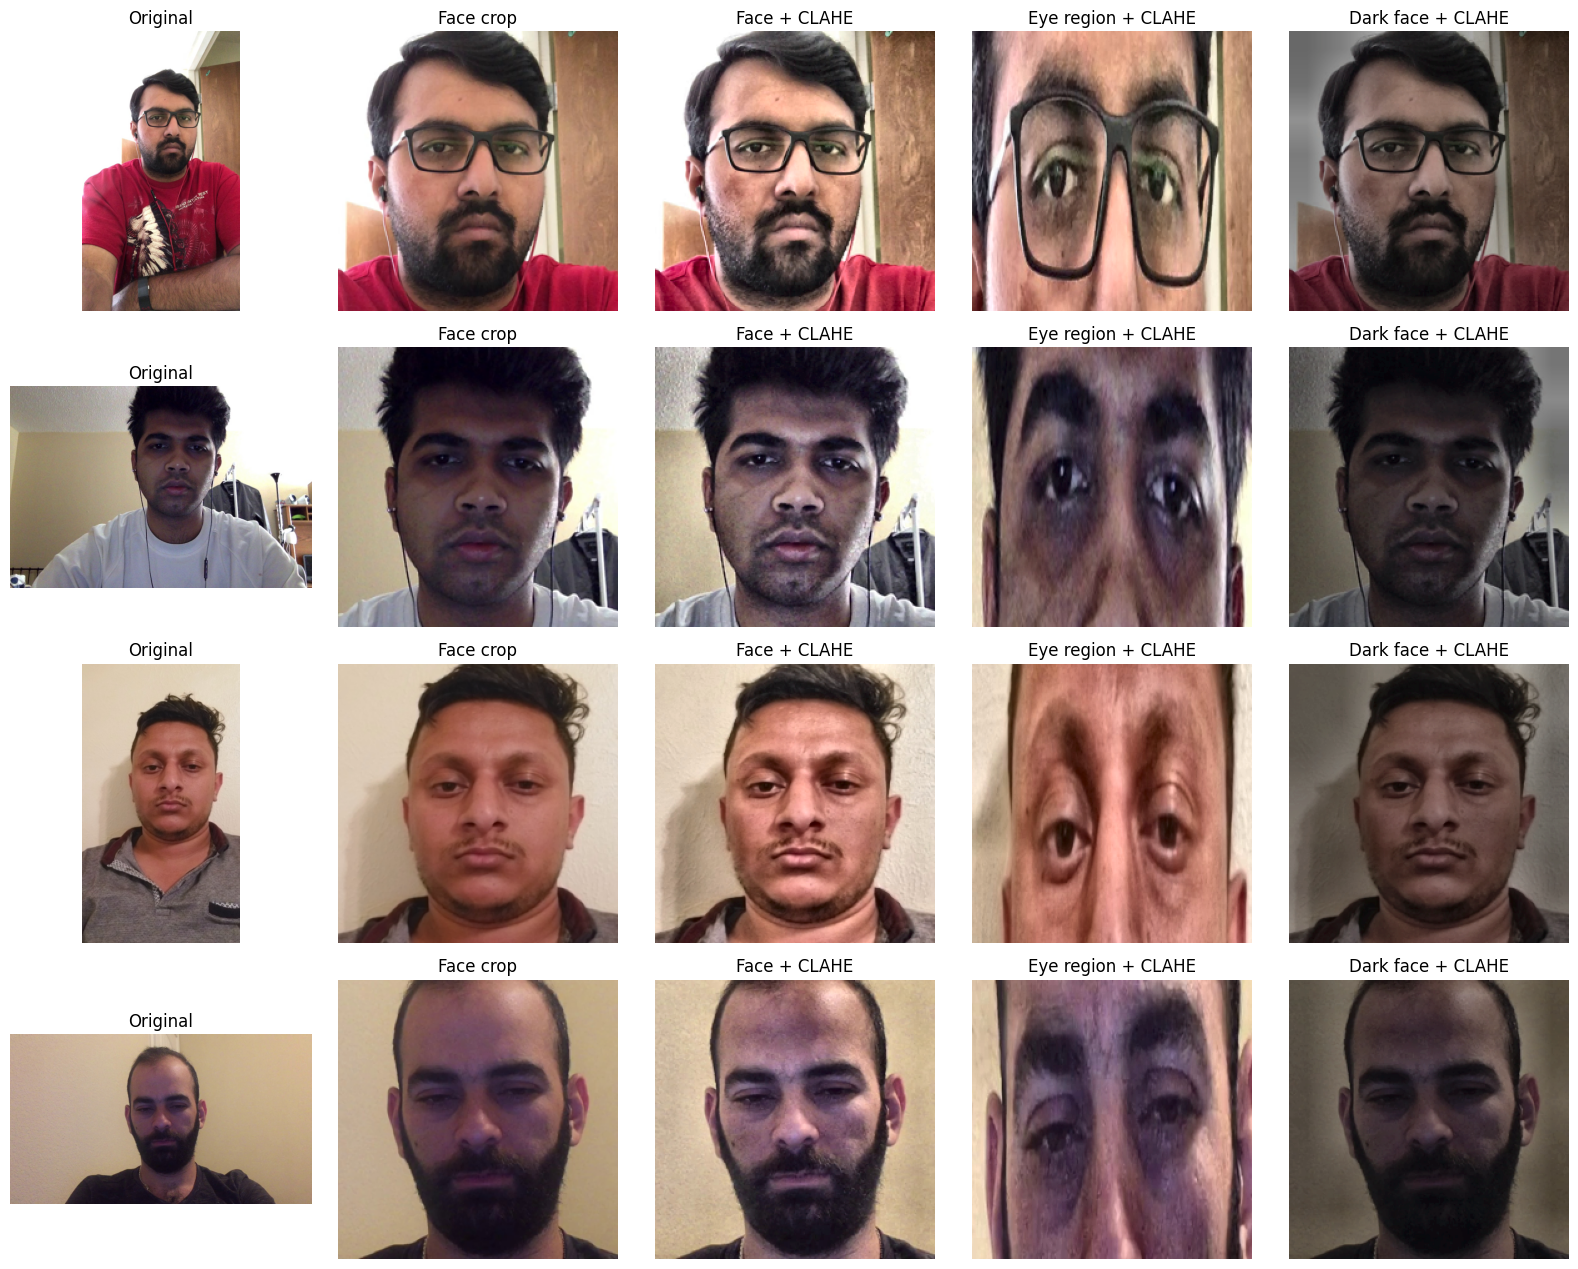

In [26]:
# Visual check of the preprocessing pipeline on a few training images.
IMG_SIZE = 224
columns = ["Original", "Face crop", "Face + CLAHE", "Eye region + CLAHE", "Dark face + CLAHE"]
sample_ids = [0, 1500, 3000, 4500]

fig, axes = plt.subplots(len(sample_ids), len(columns), figsize=(16, 3.2 * len(sample_ids)))

for row, idx in enumerate(sample_ids):
    original = dataset["train"][idx]["image"]
    face, eyes, found = crop_face_and_eyes(original)
    face = face.resize((IMG_SIZE, IMG_SIZE))

    images = [original, face, apply_clahe(face),
              apply_clahe(eyes.resize((IMG_SIZE, IMG_SIZE))),
              apply_clahe(darken(face, 0.4))]

    for col, image in enumerate(images):
        axes[row, col].imshow(image)
        axes[row, col].set_title(columns[col] if found or col == 0 else "No face found")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

### Caching the preprocessed images
Decoding large JPEGs every epoch is slow. Each image is decoded **once** and three 224×224 versions are stored in memory:
- `full` — the whole frame resized (original baseline preprocessing)
- `face` — the face crop
- `eyes` — the eye region

CLAHE is applied later, inside the dataset, so the same cache can be used with and without it. This step takes a few minutes but makes every training run much faster.

In [27]:
from tqdm.auto import tqdm

def prepare_split(hf_split):
    data = {"full": [], "face": [], "eyes": [], "labels": []}
    faces_found = 0

    for item in tqdm(hf_split, desc="Preparing images"):
        image = item["image"].convert("RGB")
        face, eyes, found = crop_face_and_eyes(image)
        faces_found += found

        data["full"].append(image.resize((IMG_SIZE, IMG_SIZE)))
        data["face"].append(face.resize((IMG_SIZE, IMG_SIZE)))
        data["eyes"].append(eyes.resize((IMG_SIZE, IMG_SIZE)))
        data["labels"].append(convert_label(item["labels"]))

    rate = 100 * faces_found / len(hf_split)
    print(f"Face detected in {faces_found}/{len(hf_split)} images ({rate:.1f}%)")
    return data


cache = {}
for split in ["train", "validation", "test"]:
    print(f"\n{split}:")
    cache[split] = prepare_split(dataset[split])


train:


Preparing images:   0%|          | 0/5539 [00:00<?, ?it/s]

Face detected in 5149/5539 images (93.0%)

validation:


Preparing images:   0%|          | 0/692 [00:00<?, ?it/s]

Face detected in 640/692 images (92.5%)

test:


Preparing images:   0%|          | 0/693 [00:00<?, ?it/s]

Face detected in 641/693 images (92.5%)


In [28]:
# Dataset that reads from the in-memory cache.
#   version = "full", "face" or "two_stream" (returns face and eye images together)
#   use_clahe = apply illumination normalization
#   dark_factor < 1.0 darkens images (only used for the low-light robustness test)
class SHIELDDataset(Dataset):
    def __init__(self, split, version, transform, use_clahe=False, dark_factor=1.0):
        self.data = cache[split]
        self.version = version
        self.transform = transform
        self.use_clahe = use_clahe
        self.dark_factor = dark_factor

    def __len__(self):
        return len(self.data["labels"])

    def prepare(self, image):
        if self.dark_factor < 1.0:
            image = darken(image, self.dark_factor)
        if self.use_clahe:
            image = apply_clahe(image)
        return self.transform(image)

    def __getitem__(self, idx):
        label = torch.tensor(self.data["labels"][idx], dtype=torch.long)

        if self.version == "two_stream":
            face = self.prepare(self.data["face"][idx])
            eyes = self.prepare(self.data["eyes"][idx])
            return (face, eyes), label

        return self.prepare(self.data[self.version][idx]), label


def make_loader(split, version, use_clahe, dark_factor=1.0):
    transform = train_transform if split == "train" else val_test_transform
    ds = SHIELDDataset(split, version, transform, use_clahe, dark_factor)
    return DataLoader(
        ds,
        batch_size=32,
        shuffle=(split == "train"),
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

## Section 12 — Models (incl. proposed Two-Stream SHIELD Network)
**Purpose:** Create the compared models with a 2-class output.

### Proposed: Two-Stream Face + Eye Network
```
Face crop (224×224) ──► MobileNetV3-Small features ──► pool (576) ─┐
                                                                   ├─► concat (1152) ─► FC 512 ─► Hardswish ─► Dropout ─► FC 2 ─► Alert / Drowsy
Eye crop  (224×224) ──► MobileNetV3-Small features ──► pool (576) ─┘
```
- The **face stream** learns global cues: yawning, head tilt, facial expression.
- The **eye stream** learns fine-grained cues: eyelid closure, squinting.
- Both branches are lightweight, so the full model remains suitable for real-time use.

| Model | Why included |
|---|---|
| MobileNetV3-Small | Original lightweight baseline |
| **Two-Stream SHIELD** | Proposed face + eye fusion model |
| EfficientNet-B0 | Efficient mid-size CNN for comparison |
| ResNet18 | Classic, widely used CNN baseline |

In [29]:
from torchvision import models


class TwoStreamSHIELD(nn.Module):
    def __init__(self):
        super().__init__()
        weights = models.MobileNet_V3_Small_Weights.DEFAULT
        self.face_features = models.mobilenet_v3_small(weights=weights).features
        self.eye_features = models.mobilenet_v3_small(weights=weights).features
        self.pool = nn.AdaptiveAvgPool2d(1)

        # 576 features from each stream -> 1152 fused features.
        self.classifier = nn.Sequential(
            nn.Linear(576 * 2, 512),
            nn.Hardswish(),
            nn.Dropout(0.2),
            nn.Linear(512, 2)
        )

    def forward(self, face, eyes):
        face_vec = self.pool(self.face_features(face)).flatten(1)
        eye_vec = self.pool(self.eye_features(eyes)).flatten(1)
        return self.classifier(torch.cat([face_vec, eye_vec], dim=1))


def build_model(name, freeze_backbone=False):
    if name == "mobilenet_v3_small":
        model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, 2)
    elif name == "two_stream":
        model = TwoStreamSHIELD()
    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
    elif name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, 2)
    else:
        raise ValueError(f"Unknown model: {name}")

    # Optionally freeze the convolutional feature extractor (transfer learning).
    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    return model.to(device)


# Quick shape check of the two-stream model.
test_model = build_model("two_stream")
dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)
print("Output shape:", test_model(dummy, dummy).shape)
print("Parameters (M):", sum(p.numel() for p in test_model.parameters()) / 1e6)
del test_model

Output shape: torch.Size([2, 2])
Parameters (M): 2.445378


## Section 13 — Training & Evaluation Functions
**Purpose:** Train a model, track loss/accuracy per epoch, keep the weights with the best validation F1-score, and evaluate on the test set.

**Metrics:** accuracy, precision, recall, F1-score (drowsy = positive class) and confusion matrix. Recall on the drowsy class is especially important, because a missed drowsy driver is the most dangerous error.

In [30]:
import copy
import time
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

EPOCHS = 8
CLASS_NAMES = ["Alert", "Drowsy"]
criterion = nn.CrossEntropyLoss()


def to_device(inputs):
    """Single-stream batches are one tensor; two-stream batches are a (face, eyes) pair."""
    if isinstance(inputs, (list, tuple)):
        return [x.to(device) for x in inputs]
    return [inputs.to(device)]


def run_epoch(model, loader, optimizer=None):
    """Runs one pass over the loader. Trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss, all_preds, all_labels = 0.0, [], []

    with torch.set_grad_enabled(training):
        for inputs, labels in loader:
            inputs, labels = to_device(inputs), labels.to(device)

            outputs = model(*inputs)
            loss = criterion(outputs, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, all_labels, all_preds


def train_model(name, version, use_clahe, freeze_backbone, lr, epochs=EPOCHS):
    torch.manual_seed(42)
    train_loader = make_loader("train", version, use_clahe)
    val_loader = make_loader("validation", version, use_clahe)

    model = build_model(name, freeze_backbone)
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()), lr=lr
    )

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_f1, best_state = -1, None

    for epoch in range(epochs):
        train_loss, y_true, y_pred = run_epoch(model, train_loader, optimizer)
        train_acc = accuracy_score(y_true, y_pred)

        val_loss, y_true, y_pred = run_epoch(model, val_loader)
        val_acc = accuracy_score(y_true, y_pred)
        val_f1 = f1_score(y_true, y_pred)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch + 1}/{epochs} | "
              f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} F1 {val_f1:.4f}")

        # Keep the best model according to validation F1-score.
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, history


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def evaluate_on_test(model, loader, title):
    _, y_true, y_pred = run_epoch(model, loader)

    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    ConfusionMatrixDisplay(
        confusion_matrix(y_true, y_pred), display_labels=CLASS_NAMES
    ).plot(cmap="Blues")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }


def measure_speed(model, runs=50):
    """Average single-image inference time on CPU (closer to an in-car device than a GPU)."""
    cpu_model = copy.deepcopy(model).cpu().eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    inputs = (x, x) if isinstance(model, TwoStreamSHIELD) else (x,)

    with torch.no_grad():
        for _ in range(5):          # warm-up runs
            cpu_model(*inputs)
        start = time.time()
        for _ in range(runs):
            cpu_model(*inputs)

    ms_per_image = (time.time() - start) / runs * 1000
    return ms_per_image, 1000 / ms_per_image

## Section 14 — Experiments (Ablation Study)
**Purpose:** Add one enhancement at a time so the contribution of each feature is visible, then compare the proposed model with other CNNs.

| # | Experiment | What it shows |
|---|---|---|
| 1 | MobileNetV3-S frozen, full frame | Original baseline (Sections 1–9) |
| 2 | MobileNetV3-S fine-tuned, full frame | Effect of fine-tuning |
| 3 | MobileNetV3-S fine-tuned, face crop | Effect of **face region extraction** |
| 4 | MobileNetV3-S fine-tuned, face crop + CLAHE | Effect of **illumination normalization** |
| 5 | **Two-Stream SHIELD**, face + eyes + CLAHE | Effect of the **eye stream / feature fusion** (proposed) |
| 6 | EfficientNet-B0 fine-tuned, face crop + CLAHE | Comparison with a larger efficient CNN |
| 7 | ResNet18 fine-tuned, face crop + CLAHE | Comparison with a classic CNN |

Frozen models use learning rate 0.001 (only the classifier is trained). Fine-tuned models use 0.0001 so the pretrained features are not destroyed.

1. MobileNetV3-S frozen (full frame)
Epoch 1/8 | train loss 0.2955 acc 0.8711 | val loss 0.0899 acc 0.9827 F1 0.9834
Epoch 2/8 | train loss 0.0614 acc 0.9838 | val loss 0.0553 acc 0.9798 F1 0.9799
Epoch 3/8 | train loss 0.0270 acc 0.9935 | val loss 0.0171 acc 0.9986 F1 0.9986
Epoch 4/8 | train loss 0.0167 acc 0.9968 | val loss 0.0149 acc 0.9986 F1 0.9986
Epoch 5/8 | train loss 0.0218 acc 0.9942 | val loss 0.0119 acc 0.9986 F1 0.9986
Epoch 6/8 | train loss 0.0228 acc 0.9924 | val loss 0.0125 acc 0.9986 F1 0.9986
Epoch 7/8 | train loss 0.0118 acc 0.9962 | val loss 0.0160 acc 0.9986 F1 0.9986
Epoch 8/8 | train loss 0.0083 acc 0.9973 | val loss 0.0164 acc 0.9986 F1 0.9986


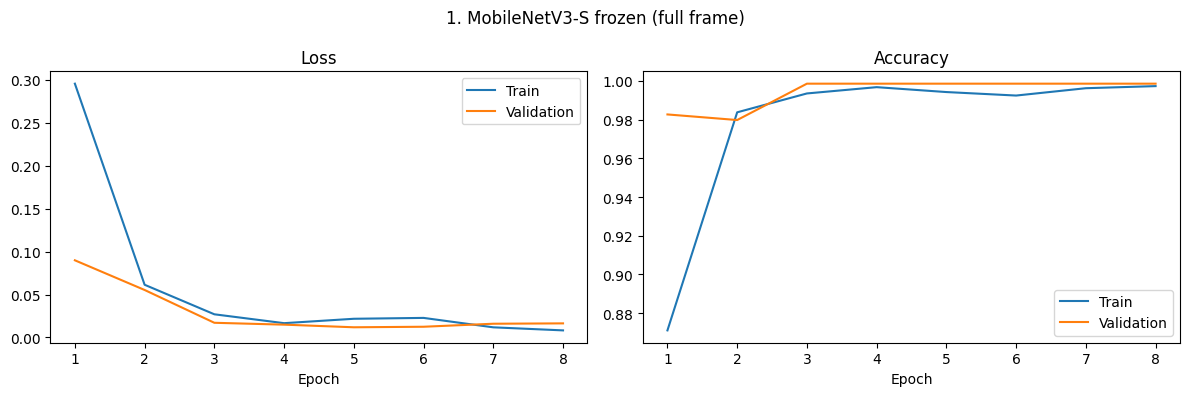

              precision    recall  f1-score   support

       Alert     0.9970    0.9941    0.9956       338
      Drowsy     0.9944    0.9972    0.9958       355

    accuracy                         0.9957       693
   macro avg     0.9957    0.9956    0.9957       693
weighted avg     0.9957    0.9957    0.9957       693



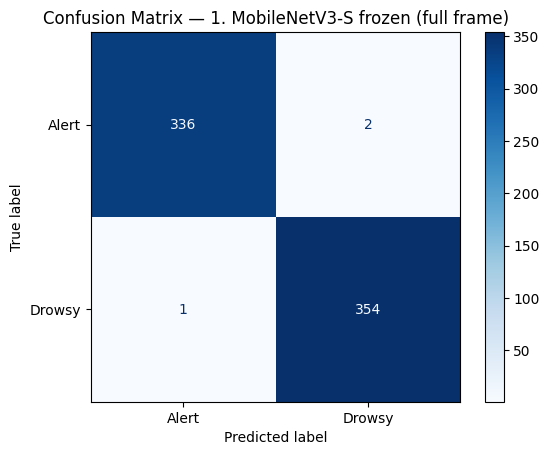

2. MobileNetV3-S fine-tuned (full frame)
Epoch 1/8 | train loss 0.2738 acc 0.9083 | val loss 0.0657 acc 0.9913 F1 0.9916
Epoch 2/8 | train loss 0.0151 acc 0.9973 | val loss 0.0194 acc 0.9971 F1 0.9972
Epoch 3/8 | train loss 0.0069 acc 0.9986 | val loss 0.0277 acc 0.9942 F1 0.9944
Epoch 4/8 | train loss 0.0059 acc 0.9989 | val loss 0.0210 acc 0.9986 F1 0.9986
Epoch 5/8 | train loss 0.0028 acc 0.9995 | val loss 0.0194 acc 0.9986 F1 0.9986
Epoch 6/8 | train loss 0.0047 acc 0.9989 | val loss 0.0238 acc 0.9986 F1 0.9986
Epoch 7/8 | train loss 0.0020 acc 0.9996 | val loss 0.0232 acc 0.9986 F1 0.9986
Epoch 8/8 | train loss 0.0032 acc 0.9986 | val loss 0.0212 acc 0.9986 F1 0.9986


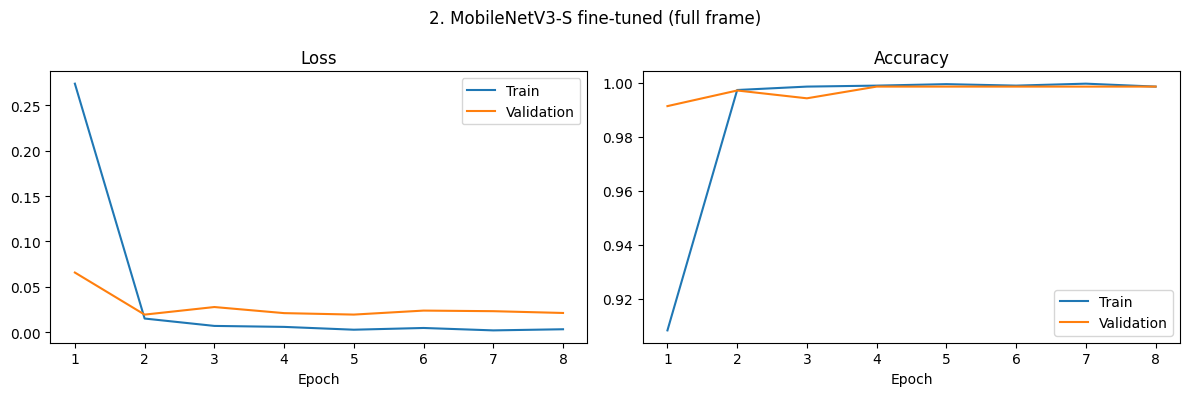

              precision    recall  f1-score   support

       Alert     1.0000    0.9970    0.9985       338
      Drowsy     0.9972    1.0000    0.9986       355

    accuracy                         0.9986       693
   macro avg     0.9986    0.9985    0.9986       693
weighted avg     0.9986    0.9986    0.9986       693



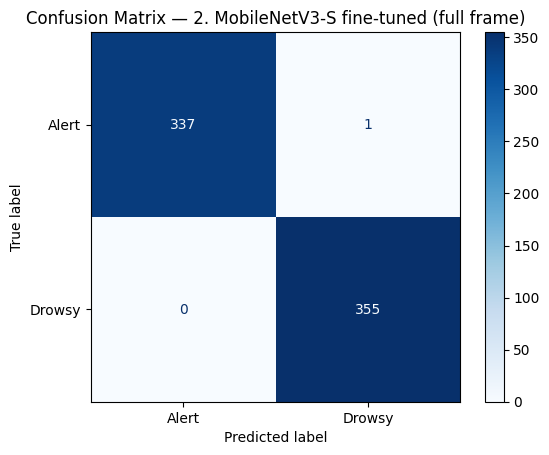

3. MobileNetV3-S (face crop)
Epoch 1/8 | train loss 0.3445 acc 0.8660 | val loss 0.1601 acc 0.9552 F1 0.9582
Epoch 2/8 | train loss 0.0418 acc 0.9893 | val loss 0.0388 acc 0.9928 F1 0.9930
Epoch 3/8 | train loss 0.0291 acc 0.9895 | val loss 0.0444 acc 0.9928 F1 0.9930
Epoch 4/8 | train loss 0.0157 acc 0.9957 | val loss 0.0290 acc 0.9942 F1 0.9944
Epoch 5/8 | train loss 0.0131 acc 0.9955 | val loss 0.0203 acc 0.9957 F1 0.9958
Epoch 6/8 | train loss 0.0101 acc 0.9966 | val loss 0.0312 acc 0.9942 F1 0.9944
Epoch 7/8 | train loss 0.0174 acc 0.9951 | val loss 0.0231 acc 0.9957 F1 0.9958
Epoch 8/8 | train loss 0.0144 acc 0.9949 | val loss 0.0254 acc 0.9957 F1 0.9958


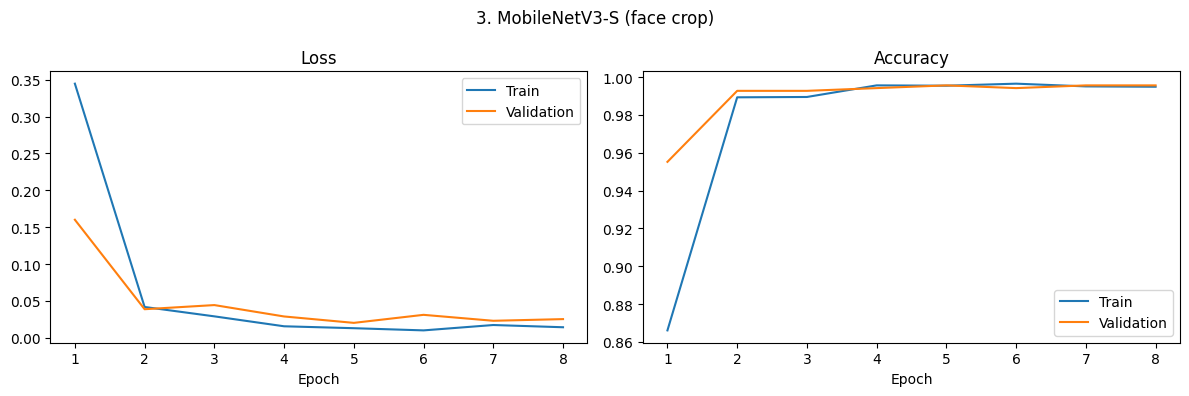

              precision    recall  f1-score   support

       Alert     0.9970    0.9941    0.9956       338
      Drowsy     0.9944    0.9972    0.9958       355

    accuracy                         0.9957       693
   macro avg     0.9957    0.9956    0.9957       693
weighted avg     0.9957    0.9957    0.9957       693



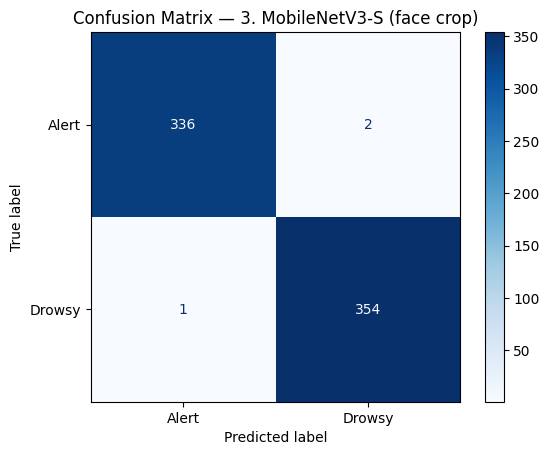

4. MobileNetV3-S (face crop + CLAHE)
Epoch 1/8 | train loss 0.3421 acc 0.8592 | val loss 0.1434 acc 0.9509 F1 0.9543
Epoch 2/8 | train loss 0.0456 acc 0.9881 | val loss 0.0373 acc 0.9928 F1 0.9930
Epoch 3/8 | train loss 0.0255 acc 0.9915 | val loss 0.0327 acc 0.9928 F1 0.9929
Epoch 4/8 | train loss 0.0163 acc 0.9933 | val loss 0.0275 acc 0.9971 F1 0.9972
Epoch 5/8 | train loss 0.0152 acc 0.9949 | val loss 0.0310 acc 0.9957 F1 0.9958
Epoch 6/8 | train loss 0.0091 acc 0.9968 | val loss 0.0308 acc 0.9971 F1 0.9972
Epoch 7/8 | train loss 0.0089 acc 0.9978 | val loss 0.0285 acc 0.9957 F1 0.9958
Epoch 8/8 | train loss 0.0117 acc 0.9949 | val loss 0.0286 acc 0.9971 F1 0.9972


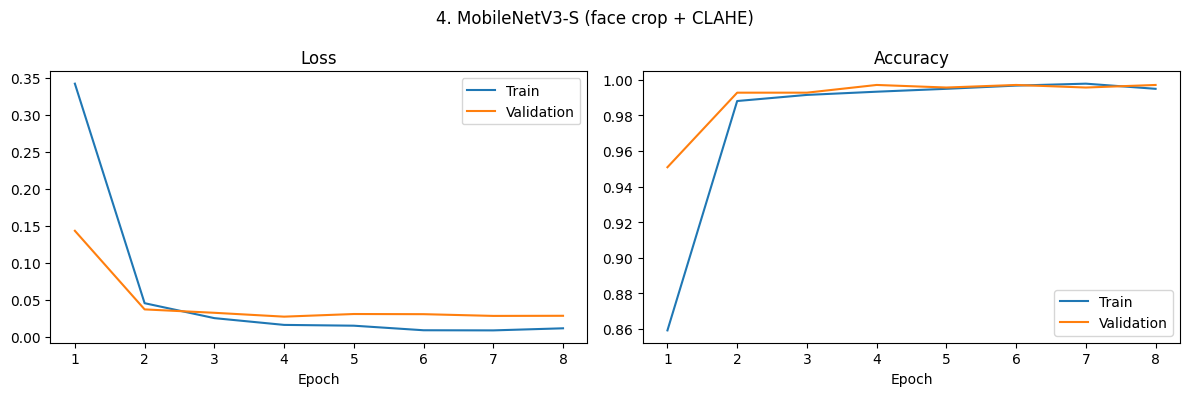

              precision    recall  f1-score   support

       Alert     0.9970    0.9970    0.9970       338
      Drowsy     0.9972    0.9972    0.9972       355

    accuracy                         0.9971       693
   macro avg     0.9971    0.9971    0.9971       693
weighted avg     0.9971    0.9971    0.9971       693



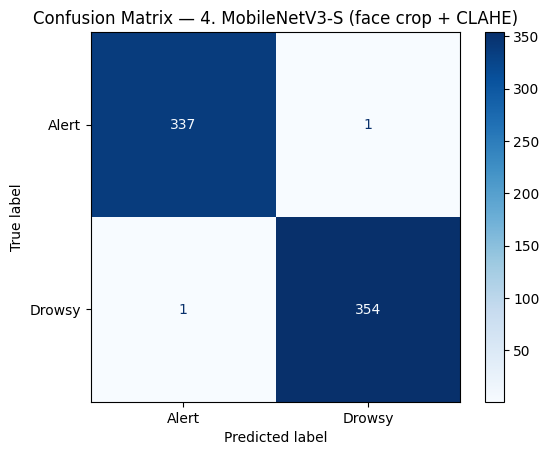

5. Two-Stream SHIELD (face + eyes + CLAHE)
Epoch 1/8 | train loss 0.3093 acc 0.8642 | val loss 0.1876 acc 0.9191 F1 0.9265
Epoch 2/8 | train loss 0.0401 acc 0.9874 | val loss 0.0969 acc 0.9581 F1 0.9608
Epoch 3/8 | train loss 0.0325 acc 0.9892 | val loss 0.0242 acc 0.9957 F1 0.9958
Epoch 4/8 | train loss 0.0149 acc 0.9951 | val loss 0.0440 acc 0.9913 F1 0.9916
Epoch 5/8 | train loss 0.0217 acc 0.9935 | val loss 0.0304 acc 0.9942 F1 0.9944
Epoch 6/8 | train loss 0.0126 acc 0.9958 | val loss 0.0284 acc 0.9957 F1 0.9958
Epoch 7/8 | train loss 0.0181 acc 0.9937 | val loss 0.0184 acc 0.9986 F1 0.9986
Epoch 8/8 | train loss 0.0065 acc 0.9978 | val loss 0.0244 acc 0.9971 F1 0.9972


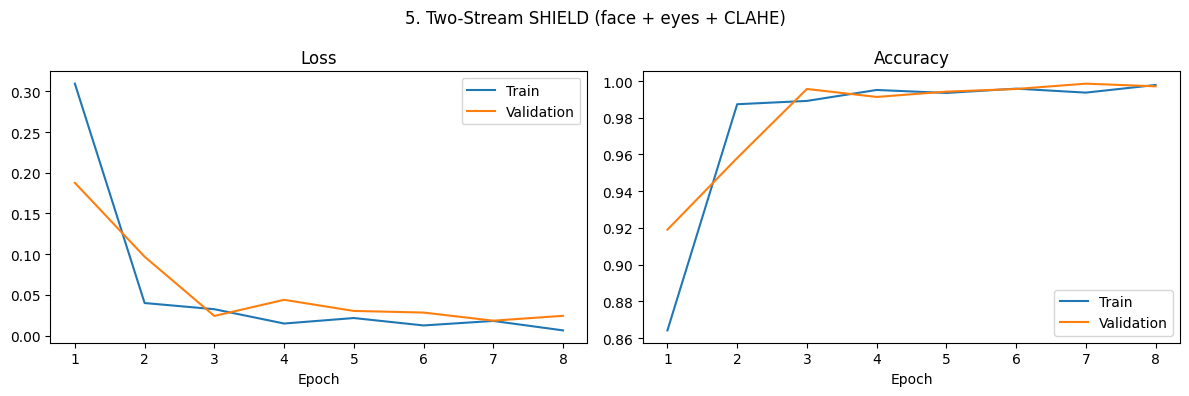

              precision    recall  f1-score   support

       Alert     0.9970    0.9970    0.9970       338
      Drowsy     0.9972    0.9972    0.9972       355

    accuracy                         0.9971       693
   macro avg     0.9971    0.9971    0.9971       693
weighted avg     0.9971    0.9971    0.9971       693



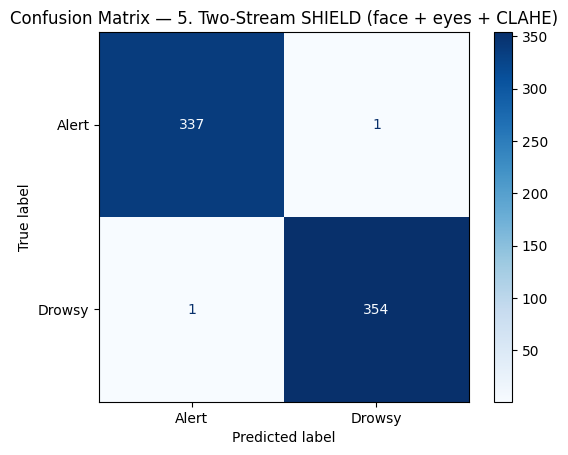

6. EfficientNet-B0 (face crop + CLAHE)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 170MB/s]


Epoch 1/8 | train loss 0.2667 acc 0.8998 | val loss 0.0282 acc 0.9928 F1 0.9930
Epoch 2/8 | train loss 0.0347 acc 0.9904 | val loss 0.0174 acc 0.9986 F1 0.9986
Epoch 3/8 | train loss 0.0235 acc 0.9933 | val loss 0.0200 acc 0.9957 F1 0.9958
Epoch 4/8 | train loss 0.0134 acc 0.9962 | val loss 0.0140 acc 0.9986 F1 0.9986
Epoch 5/8 | train loss 0.0138 acc 0.9964 | val loss 0.0150 acc 0.9986 F1 0.9986
Epoch 6/8 | train loss 0.0093 acc 0.9973 | val loss 0.0142 acc 0.9986 F1 0.9986
Epoch 7/8 | train loss 0.0080 acc 0.9980 | val loss 0.0178 acc 0.9986 F1 0.9986
Epoch 8/8 | train loss 0.0208 acc 0.9942 | val loss 0.0118 acc 0.9986 F1 0.9986


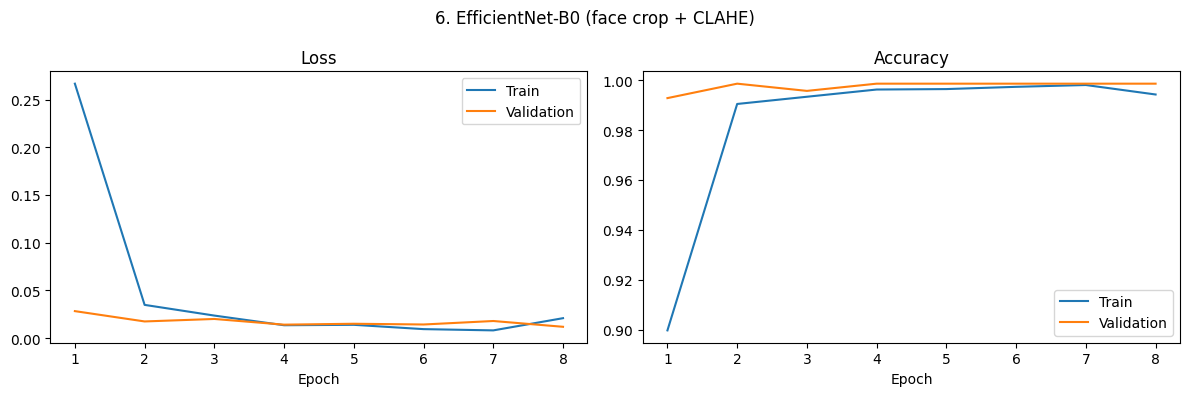

              precision    recall  f1-score   support

       Alert     0.9970    0.9941    0.9956       338
      Drowsy     0.9944    0.9972    0.9958       355

    accuracy                         0.9957       693
   macro avg     0.9957    0.9956    0.9957       693
weighted avg     0.9957    0.9957    0.9957       693



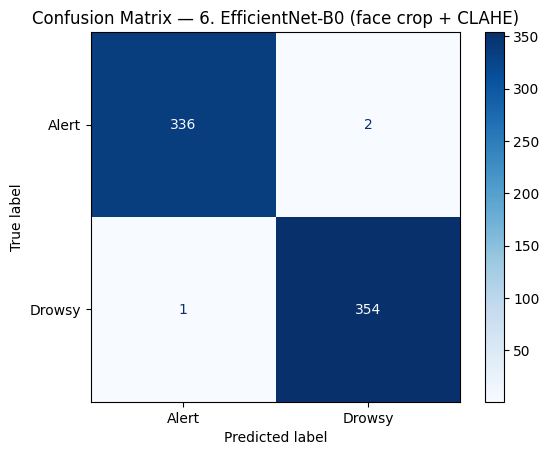

7. ResNet18 (face crop + CLAHE)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]


Epoch 1/8 | train loss 0.1425 acc 0.9462 | val loss 0.0601 acc 0.9827 F1 0.9834
Epoch 2/8 | train loss 0.0355 acc 0.9879 | val loss 0.0221 acc 0.9913 F1 0.9915
Epoch 3/8 | train loss 0.0139 acc 0.9964 | val loss 0.0094 acc 0.9942 F1 0.9944
Epoch 4/8 | train loss 0.0185 acc 0.9930 | val loss 0.0075 acc 0.9986 F1 0.9986
Epoch 5/8 | train loss 0.0217 acc 0.9913 | val loss 0.0053 acc 0.9986 F1 0.9986
Epoch 6/8 | train loss 0.0144 acc 0.9962 | val loss 0.0228 acc 0.9884 F1 0.9886
Epoch 7/8 | train loss 0.0361 acc 0.9899 | val loss 0.0115 acc 0.9957 F1 0.9958
Epoch 8/8 | train loss 0.0081 acc 0.9975 | val loss 0.0273 acc 0.9942 F1 0.9944


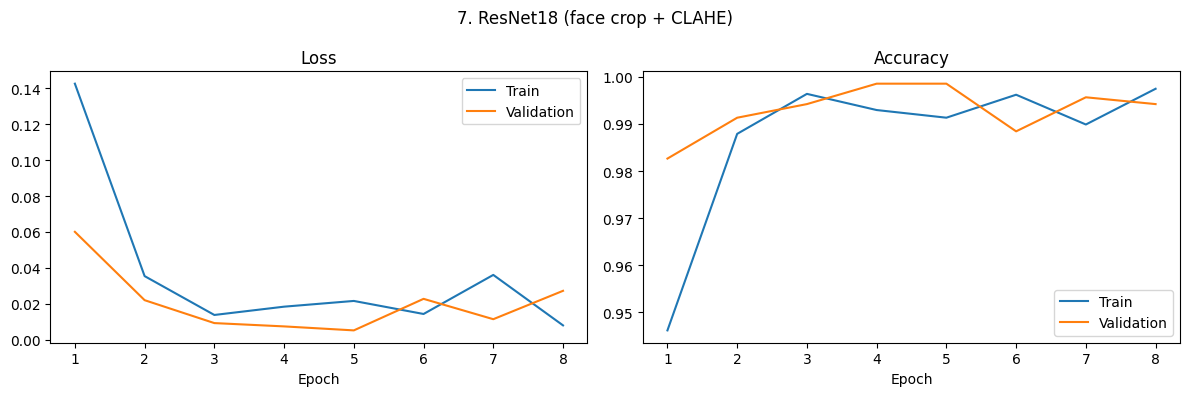

              precision    recall  f1-score   support

       Alert     0.9970    0.9970    0.9970       338
      Drowsy     0.9972    0.9972    0.9972       355

    accuracy                         0.9971       693
   macro avg     0.9971    0.9971    0.9971       693
weighted avg     0.9971    0.9971    0.9971       693



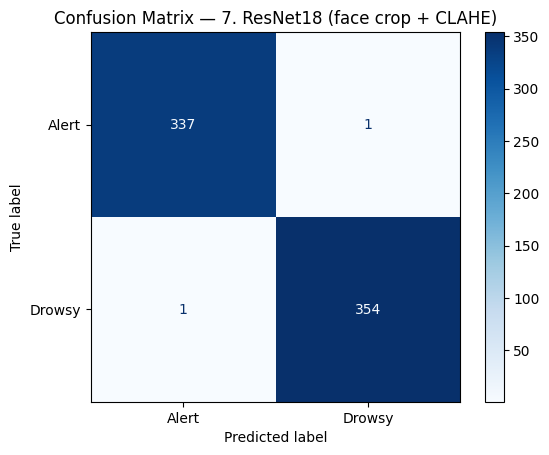

In [31]:
EXPERIMENTS = [
    # (label, model name, input version, use CLAHE, freeze backbone, learning rate)
    ("1. MobileNetV3-S frozen (full frame)", "mobilenet_v3_small", "full", False, True, 1e-3),
    ("2. MobileNetV3-S fine-tuned (full frame)", "mobilenet_v3_small", "full", False, False, 1e-4),
    ("3. MobileNetV3-S (face crop)", "mobilenet_v3_small", "face", False, False, 1e-4),
    ("4. MobileNetV3-S (face crop + CLAHE)", "mobilenet_v3_small", "face", True, False, 1e-4),
    ("5. Two-Stream SHIELD (face + eyes + CLAHE)", "two_stream", "two_stream", True, False, 1e-4),
    ("6. EfficientNet-B0 (face crop + CLAHE)", "efficientnet_b0", "face", True, False, 1e-4),
    ("7. ResNet18 (face crop + CLAHE)", "resnet18", "face", True, False, 1e-4),
]

results = []
trained = {}

for label, name, version, use_clahe, freeze, lr in EXPERIMENTS:
    print("=" * 80)
    print(label)
    print("=" * 80)

    model, history = train_model(name, version, use_clahe, freeze, lr)
    plot_history(history, label)

    test_loader = make_loader("test", version, use_clahe)
    metrics = evaluate_on_test(model, test_loader, label)
    ms, fps = measure_speed(model)
    params = sum(p.numel() for p in model.parameters()) / 1e6

    results.append({"Experiment": label, **metrics,
                    "Params (M)": params, "CPU ms/image": ms, "CPU FPS": fps})
    trained[label] = (model, version, use_clahe)

In [32]:
# Final comparison table (copy this into the paper's Results section).
results_df = pd.DataFrame(results).set_index("Experiment")
results_df.round(4)

,Accuracy,Precision,Recall,F1,Params (M),CPU ms/image,CPU FPS
Experiment,,,,,,,
1. MobileNetV3-S frozen (full frame),0.9957,0.9944,0.9972,0.9958,1.5199,11.3687,87.9607
2. MobileNetV3-S fine-tuned (full frame),0.9986,0.9972,1.0000,0.9986,1.5199,11.0516,90.4849
3. MobileNetV3-S (face crop),0.9957,0.9944,0.9972,0.9958,1.5199,11.2742,88.6981
4. MobileNetV3-S (face crop + CLAHE),0.9971,0.9972,0.9972,0.9972,1.5199,11.2655,88.7665
5. Two-Stream SHIELD (face + eyes + CLAHE),0.9971,0.9972,0.9972,0.9972,2.4454,24.1493,41.4091
6. EfficientNet-B0 (face crop + CLAHE),0.9957,0.9944,0.9972,0.9958,4.0101,40.0122,24.9924
7. ResNet18 (face crop + CLAHE),0.9971,0.9972,0.9972,0.9972,11.1775,59.6428,16.7665


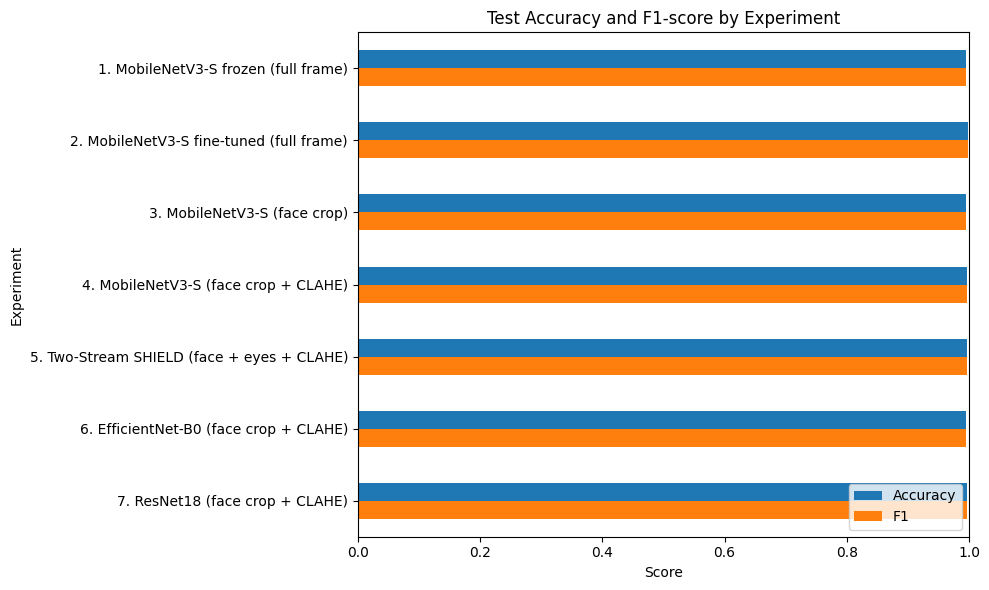

In [33]:
# Bar chart comparing test accuracy and F1-score across experiments.
results_df[["Accuracy", "F1"]].plot(kind="barh", figsize=(10, 6))
plt.title("Test Accuracy and F1-score by Experiment")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

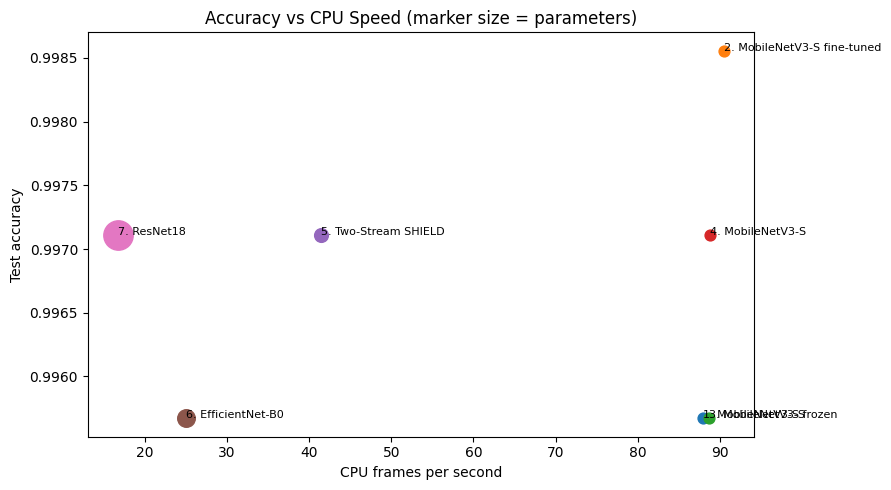

In [34]:
# Accuracy vs speed trade-off: lightweight models should sit at the top-right.
plt.figure(figsize=(9, 5))
for label, row in results_df.iterrows():
    plt.scatter(row["CPU FPS"], row["Accuracy"], s=row["Params (M)"] * 40)
    plt.annotate(label.split(" (")[0], (row["CPU FPS"], row["Accuracy"]), fontsize=8)

plt.title("Accuracy vs CPU Speed (marker size = parameters)")
plt.xlabel("CPU frames per second")
plt.ylabel("Test accuracy")
plt.tight_layout()
plt.show()

## Section 15 — Low-Light Robustness Test
**Purpose:** Measure how well each model handles a dark cabin. Every test image is darkened to **40% brightness** (simulating night or tunnel driving) and the models are evaluated again **without retraining**.

A smaller accuracy drop means the model is more robust. This directly shows the benefit of the CLAHE enhancement.

In [35]:
DARK_FACTOR = 0.4
robustness = []

for label, (model, version, use_clahe) in trained.items():
    _, y_true, y_pred = run_epoch(model, make_loader("test", version, use_clahe))
    normal_acc = accuracy_score(y_true, y_pred)

    _, y_true, y_pred = run_epoch(model, make_loader("test", version, use_clahe, DARK_FACTOR))
    dark_acc = accuracy_score(y_true, y_pred)

    robustness.append({"Experiment": label, "Normal accuracy": normal_acc,
                       "Low-light accuracy": dark_acc, "Drop": normal_acc - dark_acc})

robustness_df = pd.DataFrame(robustness).set_index("Experiment")
robustness_df.round(4)

,Normal accuracy,Low-light accuracy,Drop
Experiment,,,
1. MobileNetV3-S frozen (full frame),0.9957,0.9885,0.0072
2. MobileNetV3-S fine-tuned (full frame),0.9986,0.9856,0.0130
3. MobileNetV3-S (face crop),0.9957,0.9711,0.0245
4. MobileNetV3-S (face crop + CLAHE),0.9971,0.9264,0.0707
5. Two-Stream SHIELD (face + eyes + CLAHE),0.9971,0.9639,0.0332
6. EfficientNet-B0 (face crop + CLAHE),0.9957,0.9769,0.0188
7. ResNet18 (face crop + CLAHE),0.9971,0.9885,0.0087


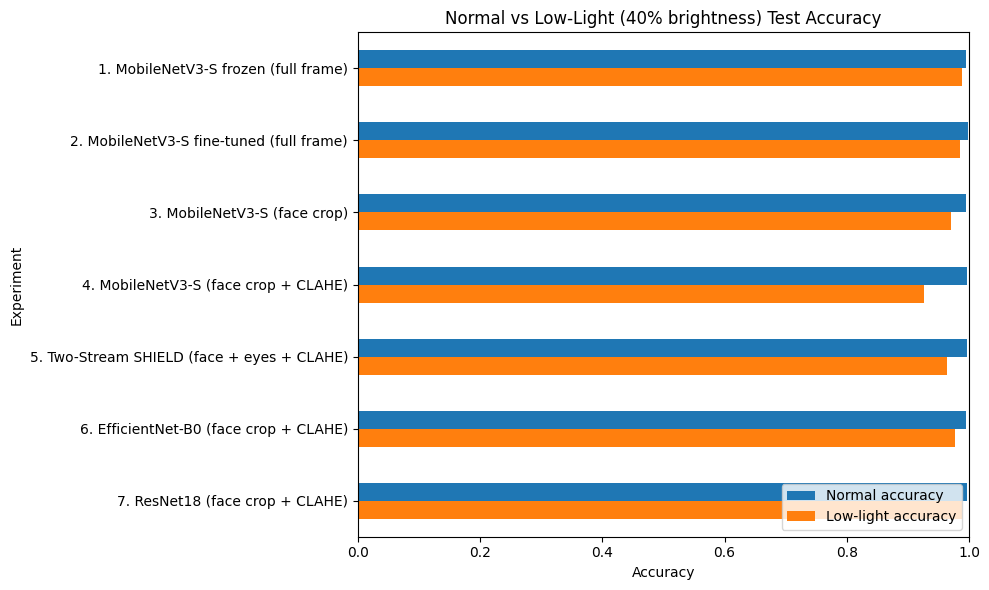

In [36]:
robustness_df[["Normal accuracy", "Low-light accuracy"]].plot(kind="barh", figsize=(10, 6))
plt.title(f"Normal vs Low-Light ({int(DARK_FACTOR * 100)}% brightness) Test Accuracy")
plt.xlabel("Accuracy")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Section 16 — Explainability with Grad-CAM
**Purpose:** Check *where* the proposed model looks when making a decision. Grad-CAM uses the gradients of the predicted class with respect to the last convolutional layer to produce a heatmap.

For the Two-Stream SHIELD model, a heatmap is produced for **both streams**: the face stream should highlight eyes/mouth, and the eye stream should highlight the eyelids.

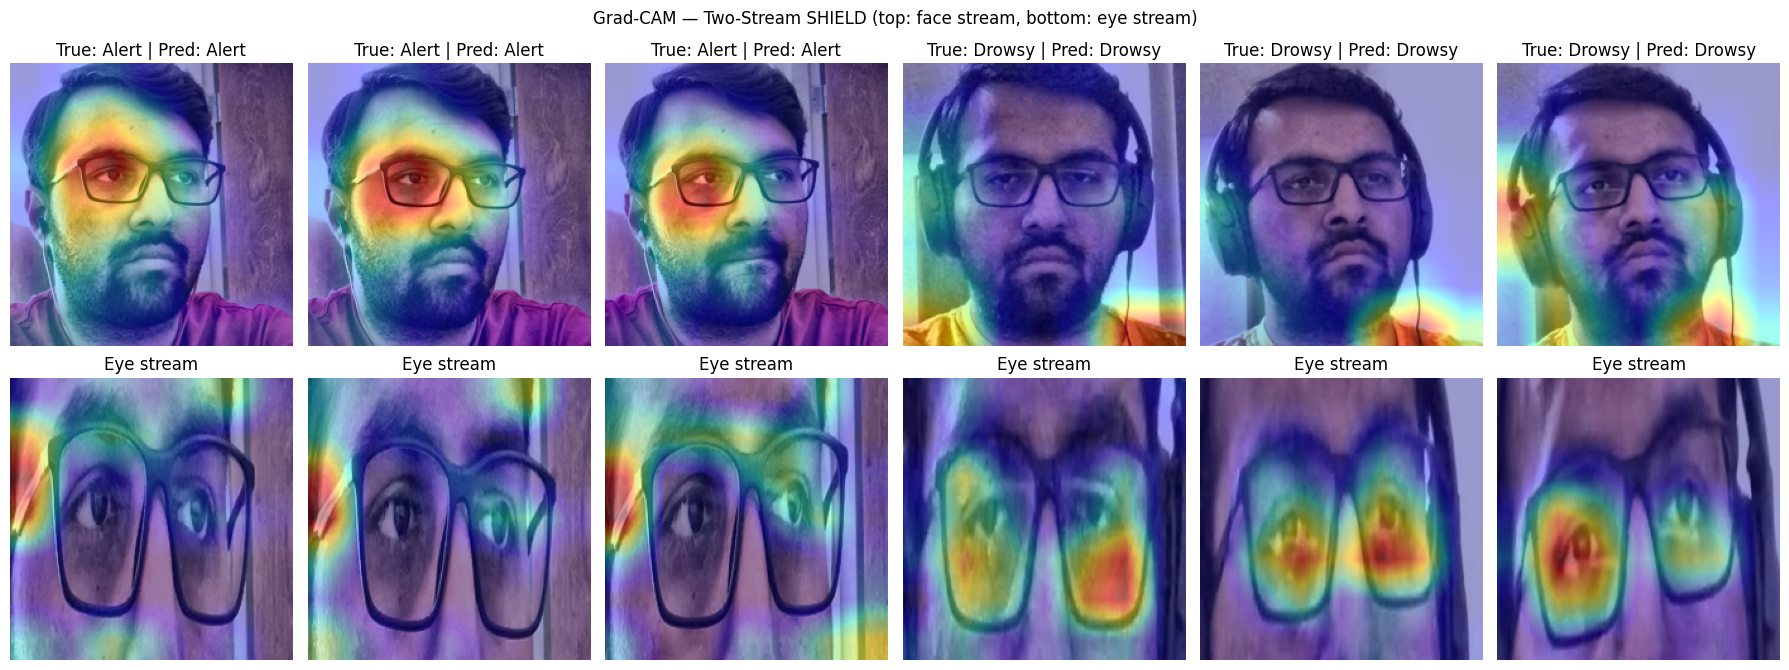

In [37]:
FINAL_LABEL = "5. Two-Stream SHIELD (face + eyes + CLAHE)"
final_model = trained[FINAL_LABEL][0]


def grad_cam(model, target_layer, inputs):
    activations, gradients = {}, {}

    def forward_hook(module, layer_inputs, output):
        activations["value"] = output
        output.register_hook(lambda grad: gradients.update(value=grad))

    handle = target_layer.register_forward_hook(forward_hook)

    model.eval()
    x = [t.unsqueeze(0).to(device).requires_grad_(True) for t in inputs]
    output = model(*x)
    pred = output.argmax(dim=1).item()

    model.zero_grad()
    output[0, pred].backward()
    handle.remove()

    # Weight each feature map by its average gradient, then combine.
    weights = gradients["value"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activations["value"]).sum(dim=1)).squeeze()
    cam = cam / (cam.max() + 1e-8)
    cam = cv2.resize(cam.detach().cpu().numpy(), (IMG_SIZE, IMG_SIZE))
    return cam, pred


# Show 3 alert and 3 drowsy test images: face stream (top) and eye stream (bottom).
test_labels = cache["test"]["labels"]
sample_idx = ([i for i, y in enumerate(test_labels) if y == 0][:3] +
              [i for i, y in enumerate(test_labels) if y == 1][:3])

fig, axes = plt.subplots(2, len(sample_idx), figsize=(18, 7))

for col, idx in enumerate(sample_idx):
    face = apply_clahe(cache["test"]["face"][idx])
    eyes = apply_clahe(cache["test"]["eyes"][idx])
    inputs = (val_test_transform(face), val_test_transform(eyes))

    face_cam, pred = grad_cam(final_model, final_model.face_features[-1], inputs)
    eye_cam, _ = grad_cam(final_model, final_model.eye_features[-1], inputs)

    axes[0, col].imshow(face)
    axes[0, col].imshow(face_cam, cmap="jet", alpha=0.4)
    axes[0, col].set_title(f"True: {CLASS_NAMES[test_labels[idx]]} | Pred: {CLASS_NAMES[pred]}")
    axes[0, col].axis("off")

    axes[1, col].imshow(eyes)
    axes[1, col].imshow(eye_cam, cmap="jet", alpha=0.4)
    axes[1, col].set_title("Eye stream")
    axes[1, col].axis("off")

plt.suptitle("Grad-CAM — Two-Stream SHIELD (top: face stream, bottom: eye stream)")
plt.tight_layout()
plt.show()

## Section 17 — Export Model for Real-Time Demo
**Purpose:** Save the final Two-Stream SHIELD model so it can be used by `demo.py` for live webcam drowsiness monitoring.

Run the demo on a laptop with a webcam:
```
pip install torch torchvision opencv-python
python demo.py --weights shield_two_stream.pth
```

In [38]:
WEIGHTS_FILE = "shield_two_stream.pth"
torch.save(final_model.state_dict(), WEIGHTS_FILE)
print("Saved:", WEIGHTS_FILE)

# Download the file when running on Google Colab.
try:
    from google.colab import files
    files.download(WEIGHTS_FILE)
except ImportError:
    pass

Saved: shield_two_stream.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion (v2)
- **Face region extraction** focuses the model on the driver instead of the full cabin frame (Experiment 3 vs 2).
- **CLAHE illumination normalization** improves visibility of facial features and robustness in low light (Experiment 4 vs 3, Section 15).
- The proposed **Two-Stream SHIELD** network fuses global face features with fine-grained eye features while staying lightweight (Experiment 5).
- Grad-CAM shows which regions of the face and eyes drive the predictions (Section 16).
- The final model runs in real time on a CPU and is demonstrated with a live webcam application (`demo.py`).

**Future work:** temporal models over video frames (CNN + LSTM/GRU), a three-level alert/low-vigilance/drowsy output, participant-wise cross-validation, and real night-time/infrared data.